# 02 · k-Nearest Neighbours (from scratch)

Implementation: `src/knn.py`. All results are on our fixed 80/20 stratified validation split.

We investigate the four design choices the project asks for:
1. **k**: 1, 3, 5, 10, 20, 50, 100, 200
2. **distance function**: Euclidean vs cosine
3. **feature normalisation**: none / standardise / L2 (sentiment) / Hellinger (image)
4. **voting**: uniform vs distance-weighted, and how strongly distance-weighted (the power `p` in 1/distance^p)

In [1]:
import sys
from pathlib import Path
ROOT = Path.cwd() if (Path.cwd() / "src").exists() else Path.cwd().parent
sys.path.insert(0, str(ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from src.common import *
from src.plotting import *
from src.knn import KNNClassifier
set_seed()

K_VALUES = [1, 3, 5, 10, 20, 50, 100, 200]
PREPROCESSING = {
    "image": ["none", "standardize", "hellinger", "hellinger+standardize"],
    "sentiment": ["none", "standardize", "l2"],
}

## Full sweep
The expensive part (distances to all 16,000 / 9,600 training points) is computed once per
(preprocessing, metric) for the largest k; every smaller k and both voting rules reuse it.

In [2]:
rows = []
for task in ("image", "sentiment"):
    Xtr, ytr, Xva, yva = get_split(task)
    for prep in PREPROCESSING[task]:
        pp = Preprocessor(prep).fit(Xtr)          # fitted on the training split only
        A, B = pp.transform(Xtr), pp.transform(Xva)
        for metric in ("euclidean", "cosine"):
            knn = KNNClassifier(metric=metric, n_classes=N_CLASSES[task]).fit(A, ytr)
            with Timer() as t:
                dist, idx = knn.kneighbors(B, k=max(K_VALUES))
            for k in K_VALUES:
                for weights in ("uniform", "distance"):
                    pred = knn.vote(dist, idx, k, weights).argmax(1)
                    rows.append(dict(task=task, preprocessing=prep, metric=metric, k=k,
                                     weights=weights, val_acc=accuracy(yva, pred)))
            print(f"{task:9s} {prep:22s} {metric:9s} neighbour search {t.seconds:.1f}s")
knn_results = pd.DataFrame(rows)
save_table(knn_results, "knn_sweep")

image     none                   euclidean neighbour search 1.2s


image     none                   cosine    neighbour search 0.9s


image     standardize            euclidean neighbour search 1.0s


image     standardize            cosine    neighbour search 0.9s


image     hellinger              euclidean neighbour search 1.0s


image     hellinger              cosine    neighbour search 1.0s


... (5 outputs left out)

sentiment standardize            cosine    neighbour search 0.4s


sentiment l2                     euclidean neighbour search 0.4s


sentiment l2                     cosine    neighbour search 0.4s


PosixPath('/home/claude/COMP472-Project/results/tables/knn_sweep.csv')

### Best configuration per preprocessing / metric

In [3]:
best_per = (knn_results.sort_values("val_acc", ascending=False)
            .groupby(["task", "preprocessing", "metric"]).head(1)
            .sort_values(["task", "val_acc"], ascending=[True, False]))
best_per

,task,preprocessing,metric,k,weights,val_acc
81,image,hellinger,cosine,1,distance,0.563000
112,image,hellinger+standardize,cosine,1,uniform,0.563000
64,image,hellinger,euclidean,1,uniform,0.562750
48,image,standardize,cosine,1,uniform,0.533250
1,image,none,euclidean,1,distance,0.519250
16,image,none,cosine,1,uniform,0.519250
96,image,hellinger+standardize,euclidean,1,uniform,0.511750
33,image,standardize,euclidean,1,distance,0.430000
219,sentiment,l2,cosine,50,distance,0.589583
155,sentiment,none,cosine,50,distance,0.589583


**Normalisation matters a lot for images.** Raw histograms give 51.9%, and the Hellinger transform gives
56.3%: taking square roots stops a few very frequent visual words from dominating the distance.
Standardising the raw histograms with Euclidean distance *hurts* (43.0%): dividing by each word's small
standard deviation blows up rare visual words, which are mostly noise. For sentiment, every
preprocessing choice and both metrics land within 0.7% of each other (58.3–59.0% at best).

### Effect of k (best metric and voting for each preprocessing)

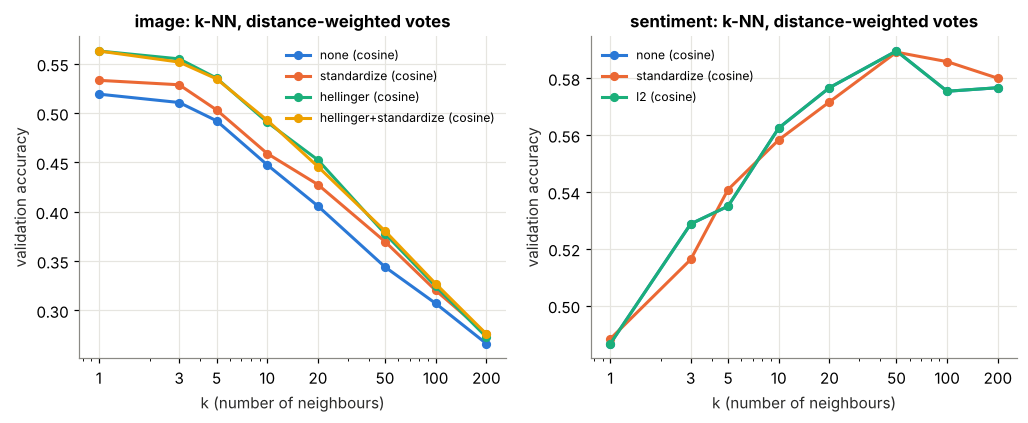

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
for ax, task in zip(axes, ("image", "sentiment")):
    r = knn_results[(knn_results.task == task) & (knn_results.weights == "distance")]
    for j, prep in enumerate(PREPROCESSING[task]):
        rp = r[r.preprocessing == prep]
        metric = rp.groupby("metric").val_acc.max().idxmax()
        rp = rp[rp.metric == metric].sort_values("k")
        ax.plot(rp.k, rp.val_acc, marker="o", color=PALETTE[j], label=f"{prep} ({metric})")
    ax.set_xscale("log"); ax.set_xticks(K_VALUES); ax.set_xticklabels(K_VALUES)
    ax.set_xlabel("k (number of neighbours)"); ax.set_ylabel("validation accuracy")
    ax.set_title(f"{task}: k-NN, distance-weighted votes")
    ax.legend(fontsize=8)
savefig(fig, "02_knn_k_curves"); plt.show()

### Uniform vs distance-weighted voting

In [5]:
pv = (knn_results.pivot_table(index=["task", "preprocessing", "metric", "k"], columns="weights", values="val_acc")
      .reset_index())
pv["distance_minus_uniform"] = pv["distance"] - pv["uniform"]
print(pv.groupby(["task", "k"]).distance_minus_uniform.mean().unstack(0).round(4))

task   image  sentiment
k                      
1     0.0000     0.0000
3     0.0002     0.0005
5     0.0030     0.0051
10    0.0104     0.0027
20    0.0145     0.0017
50    0.0114     0.0018
100   0.0108     0.0013
200   0.0093     0.0022


Distance-weighted votes essentially never hurt and help more as k grows (≈ +1–1.5% on average for
images at k ≥ 10, ≈ +0.2–0.5% for sentiment): with
many neighbours, giving the far ones less say limits the damage they do. At k = 1 the two are
identical by definition.

### Euclidean vs cosine

In [6]:
pm = knn_results.pivot_table(index=["task", "preprocessing", "k", "weights"], columns="metric", values="val_acc").reset_index()
pm["cosine_minus_euclidean"] = pm["cosine"] - pm["euclidean"]
print(pm.groupby(["task", "preprocessing"]).cosine_minus_euclidean.agg(["mean", "min", "max"]).round(4))

                                   mean     min     max
task      preprocessing                                
image     hellinger              0.0018  0.0000  0.0082
          hellinger+standardize  0.0532  0.0447  0.0603
          none                   0.0023 -0.0005  0.0107
          standardize            0.1202  0.0962  0.1418
sentiment l2                     0.0004  0.0000  0.0025
          none                   0.0013 -0.0108  0.0117
          standardize            0.0011 -0.0100  0.0150


On the raw image features the two metrics pick **exactly the same neighbours**: every vector has
length 1, and for unit vectors ‖a − b‖² = 2 − 2·cos(a, b). The tiny differences come only from
distance-weighted votes (the two distances have different values). Once features are standardised,
lengths differ and cosine (direction only) is clearly better for images (+4–6% after Hellinger +
standardising, +10–14% after standardising alone).

## How strongly should closer neighbours count? (distance-weight power)
Standard distance weighting uses weight = 1/distance. We also try 1/distance^p for larger p,
which lets the closest few neighbours dominate while the rest still break near-ties.
Run with each task's best preprocessing and metric from the sweep above.

In [7]:
POWERS = [1, 2, 4, 8, 16]
rows = []
for task in ("image", "sentiment"):
    r0 = knn_results[knn_results.task == task].sort_values("val_acc", ascending=False).iloc[0]
    Xtr, ytr, Xva, yva = get_split(task)
    pp = Preprocessor(r0.preprocessing).fit(Xtr)
    knn = KNNClassifier(metric=r0.metric, n_classes=N_CLASSES[task]).fit(pp.transform(Xtr), ytr)
    dist, idx = knn.kneighbors(pp.transform(Xva), k=max(K_VALUES))
    for k in K_VALUES[1:]:
        for pw in POWERS:
            rows.append(dict(task=task, preprocessing=r0.preprocessing, metric=r0.metric, k=k,
                             weights="distance", power=pw,
                             val_acc=accuracy(yva, knn.vote(dist, idx, k, "distance", pw).argmax(1))))
power_results = pd.DataFrame(rows)
save_table(power_results, "knn_power_sweep")
for task in ("image", "sentiment"):
    print(task)
    print(power_results[power_results.task == task].pivot(index="k", columns="power", values="val_acc").round(4))

image
power      1       2       4       8       16
k                                            
3      0.5518  0.5535  0.5585  0.5638  0.5672
5      0.5347  0.5395  0.5550  0.5668  0.5728
10     0.4928  0.5025  0.5365  0.5658  0.5780
20     0.4458  0.4640  0.5112  0.5588  0.5788
50     0.3805  0.4090  0.4652  0.5448  0.5768
100    0.3270  0.3565  0.4278  0.5285  0.5805
200    0.2760  0.3020  0.3832  0.5012  0.5780
sentiment
power      1       2       4       8       16
k                                            
3      0.5288  0.5300  0.5250  0.5188  0.5071
5      0.5350  0.5337  0.5312  0.5329  0.5154
10     0.5625  0.5646  0.5604  0.5550  0.5212
20     0.5767  0.5767  0.5742  0.5612  0.5329
50     0.5896  0.5933  0.5933  0.5808  0.5417
100    0.5754  0.5829  0.5908  0.5908  0.5475
200    0.5767  0.5762  0.5850  0.5892  0.5517


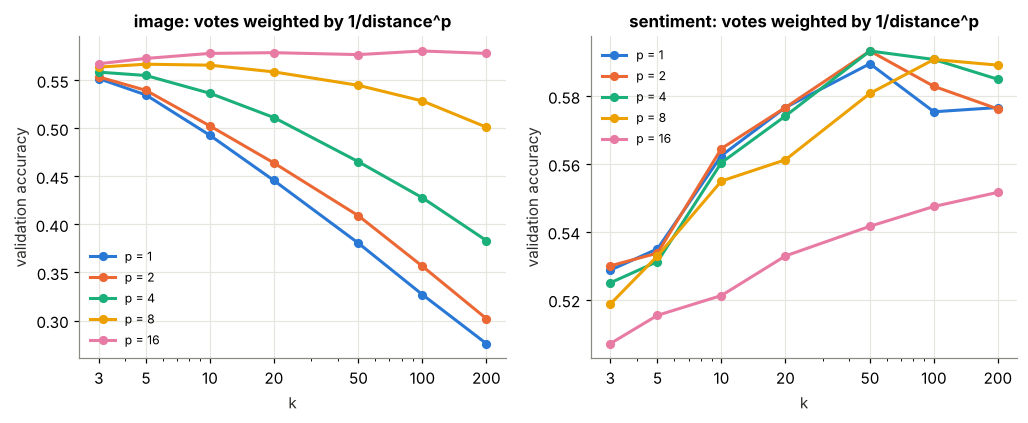

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
for ax, task in zip(axes, ("image", "sentiment")):
    r = power_results[power_results.task == task]
    for j, pw in enumerate(POWERS):
        rp = r[r.power == pw].sort_values("k")
        ax.plot(rp.k, rp.val_acc, marker="o", color=PALETTE[j], label=f"p = {pw}")
    ax.set_xscale("log"); ax.set_xticks(K_VALUES[1:]); ax.set_xticklabels(K_VALUES[1:])
    ax.set_xlabel("k"); ax.set_ylabel("validation accuracy")
    ax.set_title(f"{task}: votes weighted by 1/distance^p")
    ax.legend(fontsize=8)
savefig(fig, "02_knn_power"); plt.show()

For images, a high power (p = 16) is best at every k and makes large k work (58.1% at k = 100 vs 56.3%
for 1-NN): the closest neighbours dominate, and the rest only break near-ties. For sentiment, mild
weighting (p = 2–4) is best and very high powers hurt, because there averaging many votes is what helps.

## Over- vs under-fitting as k changes
"Training accuracy" here means predicting training points with the training set as memory, so
each point is its own nearest neighbour. k = 1 therefore scores 100% on training data: pure memorisation.

In [9]:
all_results = pd.concat([knn_results.assign(power=1), power_results], ignore_index=True)
best = {}
for task in ("image", "sentiment"):
    r = all_results[all_results.task == task].sort_values("val_acc", ascending=False).iloc[0]
    best[task] = r
    print(task, "best:", dict(r))

rows = []
for task in ("image", "sentiment"):
    b = best[task]
    Xtr, ytr, Xva, yva = get_split(task)
    pp = Preprocessor(b.preprocessing).fit(Xtr)
    A, B = pp.transform(Xtr), pp.transform(Xva)
    knn = KNNClassifier(metric=b.metric, n_classes=N_CLASSES[task]).fit(A, ytr)
    sub = np.random.default_rng(SEED).choice(len(A), 3000, replace=False)
    d_tr, i_tr = knn.kneighbors(A[sub], k=max(K_VALUES))
    d_va, i_va = knn.kneighbors(B, k=max(K_VALUES))
    for k in K_VALUES:
        rows.append(dict(task=task, k=k,
                         train_acc=accuracy(ytr[sub], knn.vote(d_tr, i_tr, k, "uniform").argmax(1)),
                         val_acc=accuracy(yva, knn.vote(d_va, i_va, k, "uniform").argmax(1))))
fit_curve = pd.DataFrame(rows)
save_table(fit_curve, "knn_train_vs_val")
fit_curve.pivot(index="k", columns="task", values=["train_acc", "val_acc"]).round(3)

image best: {'task': 'image', 'preprocessing': 'hellinger+standardize', 'metric': 'cosine', 'k': np.int64(100), 'weights': 'distance', 'val_acc': np.float64(0.5805), 'power': np.int64(16)}
sentiment best: {'task': 'sentiment', 'preprocessing': 'none', 'metric': 'cosine', 'k': np.int64(50), 'weights': 'distance', 'val_acc': np.float64(0.5933333333333334), 'power': np.int64(2)}


train_acc           val_acc          
task     image sentiment   image sentiment
k                                         
1        1.000     1.000   0.563     0.487
3        0.967     0.807   0.552     0.528
5        0.886     0.744   0.531     0.527
10       0.743     0.668   0.480     0.558
20       0.609     0.640   0.428     0.574
50       0.472     0.608   0.366     0.586
100      0.377     0.587   0.314     0.573
200      0.308     0.576   0.264     0.575

k = 1 memorises: 100% on training points (each is its own neighbour). For **images**, validation
accuracy is also highest at small k and falls steadily as k grows: large k **underfits** by blurring
neighbouring groups together. For **sentiment**, k = 1 is the worst (48.7%): one neighbour is a noisy
vote, i.e. **overfitting** to individual training tweets. Accuracy improves up to k ≈ 50 and then flattens.

## Why do the very closest neighbours matter so much for images, but not for sentiment?
Look at the 1-nearest-neighbour prediction, grouped by **how close** that nearest neighbour is.
If many validation images have a close relative in the training set (e.g. another photo of the
same object), 1-NN should be almost always right for those.

In [10]:
rows = []
for task in ("image", "sentiment"):
    b = best[task]
    Xtr, ytr, Xva, yva = get_split(task)
    pp = Preprocessor(b.preprocessing).fit(Xtr)
    knn = KNNClassifier(metric=b.metric, n_classes=N_CLASSES[task]).fit(pp.transform(Xtr), ytr)
    d, i = knn.kneighbors(pp.transform(Xva), k=1)
    d, correct = d[:, 0], ytr[i[:, 0]] == yva
    q = pd.qcut(d, 5, labels=["closest 20%", "2nd", "3rd", "4th", "farthest 20%"])
    for lab in q.categories:
        m = np.asarray(q == lab)
        rows.append(dict(task=task, nearest_neighbour_distance=lab, one_nn_accuracy=correct[m].mean(),
                         median_distance=np.median(d[m])))
nn_dist = pd.DataFrame(rows)
save_table(nn_dist, "knn_accuracy_by_nn_distance")
nn_dist.pivot(index="nearest_neighbour_distance", columns="task", values="one_nn_accuracy").round(3)

task,image,sentiment
nearest_neighbour_distance,,
2nd,0.716,0.525
3rd,0.618,0.465
4th,0.402,0.479
closest 20%,0.876,0.521
farthest 20%,0.202,0.444


**Images:** when the nearest training image is very close (the closest 20% of validation images),
1-NN is right almost 9 times out of 10. When it is far, 1-NN is right only about 1 time in 5. So each
image class looks like many small, tight groups of near-relatives (plausibly several photos of the
same object). If a validation image has a relative in the training set, its single closest neighbour
finds it; adding more equal votes only brings in other groups, often from other classes. That is why
accuracy *falls* as k grows with equal votes, and why the best setting is a large k with very strong
distance weighting (1/distance¹⁶), which in effect means "listen to the closest few".

**Sentiment:** how close the nearest neighbour is barely predicts whether it is right. There are no
tight groups, and labels are noisy, so it pays to average the votes of many neighbours (k ≈ 50).

## Final k-NN model per task: save validation predictions and timings

In [11]:
summary = []
for task in ("image", "sentiment"):
    b = best[task]
    Xtr, ytr, Xva, yva = get_split(task)
    pp = Preprocessor(b.preprocessing).fit(Xtr)
    with Timer() as t_fit:
        A = pp.transform(Xtr)
        knn = KNNClassifier(k=int(b.k), metric=b.metric, weights=b.weights, power=float(b.power),
                            n_classes=N_CLASSES[task]).fit(A, ytr)
    with Timer() as t_pred:
        proba = knn.predict_proba(pp.transform(Xva))
    pred = proba.argmax(1)
    cfg = dict(preprocessing=b.preprocessing, metric=b.metric, k=int(b.k), weights=b.weights, power=float(b.power))
    info = dict(model="k-NN", config=cfg, val_acc=accuracy(yva, pred),
                fit_seconds=t_fit.seconds, predict_seconds=t_pred.seconds)
    save_val_predictions(task, "knn", pred, proba, info)
    summary.append(dict(task=task, **cfg, val_acc=info["val_acc"],
                        fit_s=round(t_fit.seconds, 2), predict_s=round(t_pred.seconds, 2)))
pd.DataFrame(summary)

,task,preprocessing,metric,k,weights,power,val_acc,fit_s,predict_s
0,image,hellinger+standardize,cosine,100,distance,16.0,0.580500,0.09,0.96
1,sentiment,none,cosine,50,distance,2.0,0.593333,0.02,0.40
